# Thesis results: occupant feedback and dynamic comfort

These are the saved final thesis results for 25 Vermont homes, from `ce1_occ_p2s2_all_occ`. January supplies commissioning data; February and March are deployment months. Run all cells to read the versioned CSVs and figures. This notebook does not train or simulate controllers. See [reproduction and provenance](../docs/reproduction.md) and the [artifact manifest](artifact_manifest.json).

Four simulated occupant types (tolerant, sensitive, cold-preferring, and hot-preferring) generate stochastic thermostat overrides. `without_tdyn` uses the schedule and overrides; `bspline_tdyn` uses occupancy-gated, preference-anchored dynamic references.

Table IX reports the B-spline dynamic-reference cases. Cold, hot, and comfort columns are auxiliary band-violation indicators. In these preference-shifted cases, KH and override starts are closer to the occupant feedback signal; a high band-violation percentage alone does not establish preference dissatisfaction. These are simulation models, not field-validated human-subject models.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'analysis/artifact_manifest.json').is_file())
DATA = ROOT / 'analysis/data'
FIGURES = ROOT / 'analysis/figures'
pd.set_option('display.max_columns', None)
pd.set_option('display.precision', 2)


## Table IX — February

In [2]:
display(pd.read_csv(DATA / 'ce1_thesis_final_results_occupant_controller_mean_kpis_february.csv'))

,occupant,controller,Elec. score,Daily peak,Max peak,Ramping,1-LF,Grid,Cold [%],Hot [%],Comfort [%],KH,Mean overrides/building
0,occ1 tolerant,GNU-RL,1.16,1.09,1.04,1.07,0.94,1.04,1.32,48.67,49.99,521.67,6.48
1,occ1 tolerant,MPC,1.16,1.09,1.04,1.06,0.93,1.03,1.39,48.47,49.86,484.68,6.32
2,occ1 tolerant,SAC,1.06,1.04,1.00,1.12,1.00,1.04,35.33,1.49,36.81,1117.24,20.16
3,occ1 tolerant,Safe-PI,0.90,1.28,1.08,2.73,1.30,1.60,21.28,28.47,49.75,2101.85,56.36
4,occ2 sensitive,GNU-RL,1.24,1.14,1.06,1.09,0.92,1.05,1.26,67.55,68.82,596.69,38.76
5,occ2 sensitive,MPC,1.26,1.14,1.06,1.07,0.90,1.04,1.73,66.80,68.54,572.41,36.56
6,occ2 sensitive,SAC,1.11,1.08,1.01,1.18,0.99,1.06,38.90,0.35,39.25,1201.69,95.64
7,occ2 sensitive,Safe-PI,0.96,1.34,1.14,2.89,1.28,1.66,25.52,29.81,55.32,2290.41,112.08
8,occ3 cold,GNU-RL,1.03,1.02,1.00,1.06,1.00,1.02,12.54,23.65,36.19,481.18,17.92
9,occ3 cold,MPC,1.02,1.02,1.00,1.05,0.99,1.02,13.33,23.38,36.71,434.42,16.40


## Table IX — March

In [3]:
display(pd.read_csv(DATA / 'ce1_thesis_final_results_occupant_controller_mean_kpis_march.csv'))

,occupant,controller,Elec. score,Daily peak,Max peak,Ramping,1-LF,Grid,Cold [%],Hot [%],Comfort [%],KH,Mean overrides/building
0,occ1 tolerant,GNU-RL,1.21,1.10,1.06,1.04,0.92,1.03,0.93,47.48,48.41,582.26,6.88
1,occ1 tolerant,MPC,1.22,1.10,1.05,1.01,0.91,1.02,0.78,47.81,48.59,548.38,5.84
2,occ1 tolerant,SAC,1.13,1.08,1.04,1.14,0.97,1.06,13.56,0.55,14.12,820.75,11.72
3,occ1 tolerant,Safe-PI,0.89,1.21,1.06,2.70,1.25,1.56,20.94,22.76,43.70,1923.40,51.92
4,occ2 sensitive,GNU-RL,1.31,1.15,1.08,1.05,0.89,1.04,0.92,67.66,68.57,677.67,42.80
5,occ2 sensitive,MPC,1.32,1.14,1.08,1.03,0.87,1.03,0.59,68.45,69.04,642.65,38.44
6,occ2 sensitive,SAC,1.23,1.13,1.06,1.21,0.95,1.09,15.34,0.86,16.20,899.66,75.04
7,occ2 sensitive,Safe-PI,0.96,1.25,1.09,2.86,1.23,1.61,25.85,23.93,49.78,2103.72,123.76
8,occ3 cold,GNU-RL,1.05,1.03,1.03,1.03,0.98,1.02,9.71,20.89,30.60,529.42,21.28
9,occ3 cold,MPC,1.05,1.02,1.02,1.01,0.97,1.00,9.90,20.78,30.68,487.39,17.36


## Paired override comparisons for every building

In [4]:
display(pd.read_csv(DATA / 'ce1_occ_p2s2_all_occ_override_deltas.csv'))

,month,controller,building,building_id,occupant,overrides_without,overrides_bspline,delta_overrides,override_hours_without,override_hours_bspline,delta_override_hours,discomfort_without,discomfort_bspline,delta_discomfort_proportion,electricity_consumption_without,electricity_consumption_bspline,delta_electricity_consumption_total
0,February,MPC,Building 1,building_01,occ1_tolerant,38.0,2.0,-36.0,109.0,6.0,-103.0,3.28e-02,0.46,0.42,0.97,1.16,0.19
1,February,MPC,Building 2,building_02,occ1_tolerant,13.0,4.0,-9.0,39.0,10.0,-29.0,1.24e-02,0.26,0.25,1.02,1.15,0.13
2,February,MPC,Building 3,building_03,occ1_tolerant,97.0,5.0,-92.0,285.0,15.0,-270.0,1.64e-01,0.95,0.79,1.02,1.38,0.36
3,February,MPC,Building 4,building_04,occ1_tolerant,31.0,11.0,-20.0,93.0,33.0,-60.0,2.17e-02,0.45,0.42,1.00,1.15,0.15
4,February,MPC,Building 5,building_05,occ1_tolerant,13.0,8.0,-5.0,37.0,22.0,-15.0,2.99e-03,0.11,0.11,1.04,0.95,-0.09
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,March,Safe-PI/RBC,Building 21,building_21,occ4_hot,130.0,110.0,-20.0,642.0,709.0,67.0,5.13e-01,0.48,-0.03,0.76,0.86,0.09
996,March,Safe-PI/RBC,Building 22,building_22,occ4_hot,112.0,118.0,6.0,633.0,716.0,83.0,4.69e-01,0.64,0.17,0.84,0.94,0.10
997,March,Safe-PI/RBC,Building 23,building_23,occ4_hot,110.0,89.0,-21.0,631.0,698.0,67.0,3.21e-01,0.38,0.06,0.84,0.90,0.06
998,March,Safe-PI/RBC,Building 24,building_24,occ4_hot,151.0,128.0,-23.0,653.0,727.0,74.0,3.63e-01,0.62,0.26,0.89,1.12,0.23


In [5]:
overrides = pd.read_csv(DATA / 'ce1_occ_p2s2_all_occ_override_deltas.csv')
summary = overrides.groupby(['month', 'controller'])[['overrides_without', 'overrides_bspline']].sum()
summary['reduction_pct_from_totals'] = 100 * (1 - summary['overrides_bspline'] / summary['overrides_without'])
display(summary)


overrides_without  overrides_bspline  \
month    controller                                                    
February GNU-RL adaptive model             8211.0             2433.0   
         GNU-RL fixed model                8095.0             2455.0   
         MPC                               9094.0             2224.0   
         SAC                               9793.0             6508.0   
         Safe-PI/RBC                      10280.0             9077.0   
March    GNU-RL adaptive model             8976.0             2636.0   
         GNU-RL fixed model                9175.0             2612.0   
         MPC                              10084.0             2321.0   
         SAC                               9163.0             4393.0   
         Safe-PI/RBC                      11130.0             9537.0   

                                reduction_pct_from_totals  
month    controller                                        
February GNU-RL adaptive model                      70.37  
         GNU-RL fixed model                         69.67  
         MPC                                        75.54  
         SAC                                        33.54  
         Safe-PI/RBC                                11.70  
March    GNU-RL adaptive model                      70.63  
         GNU-RL fixed model                         71.53  
         MPC                                        76.98  
         SAC                                        52.06  
         Safe-PI/RBC                                14.31

The calculation above uses pooled override counts per controller and month. Its averaging convention is explicit; it can differ from an average of individual percentage reductions. The thesis reports approximately 78% reduction for MPC and 72% for GNU-RL, versus 14% for Safe-PI/RBC.

## MPC occupant response in the same representative buildings

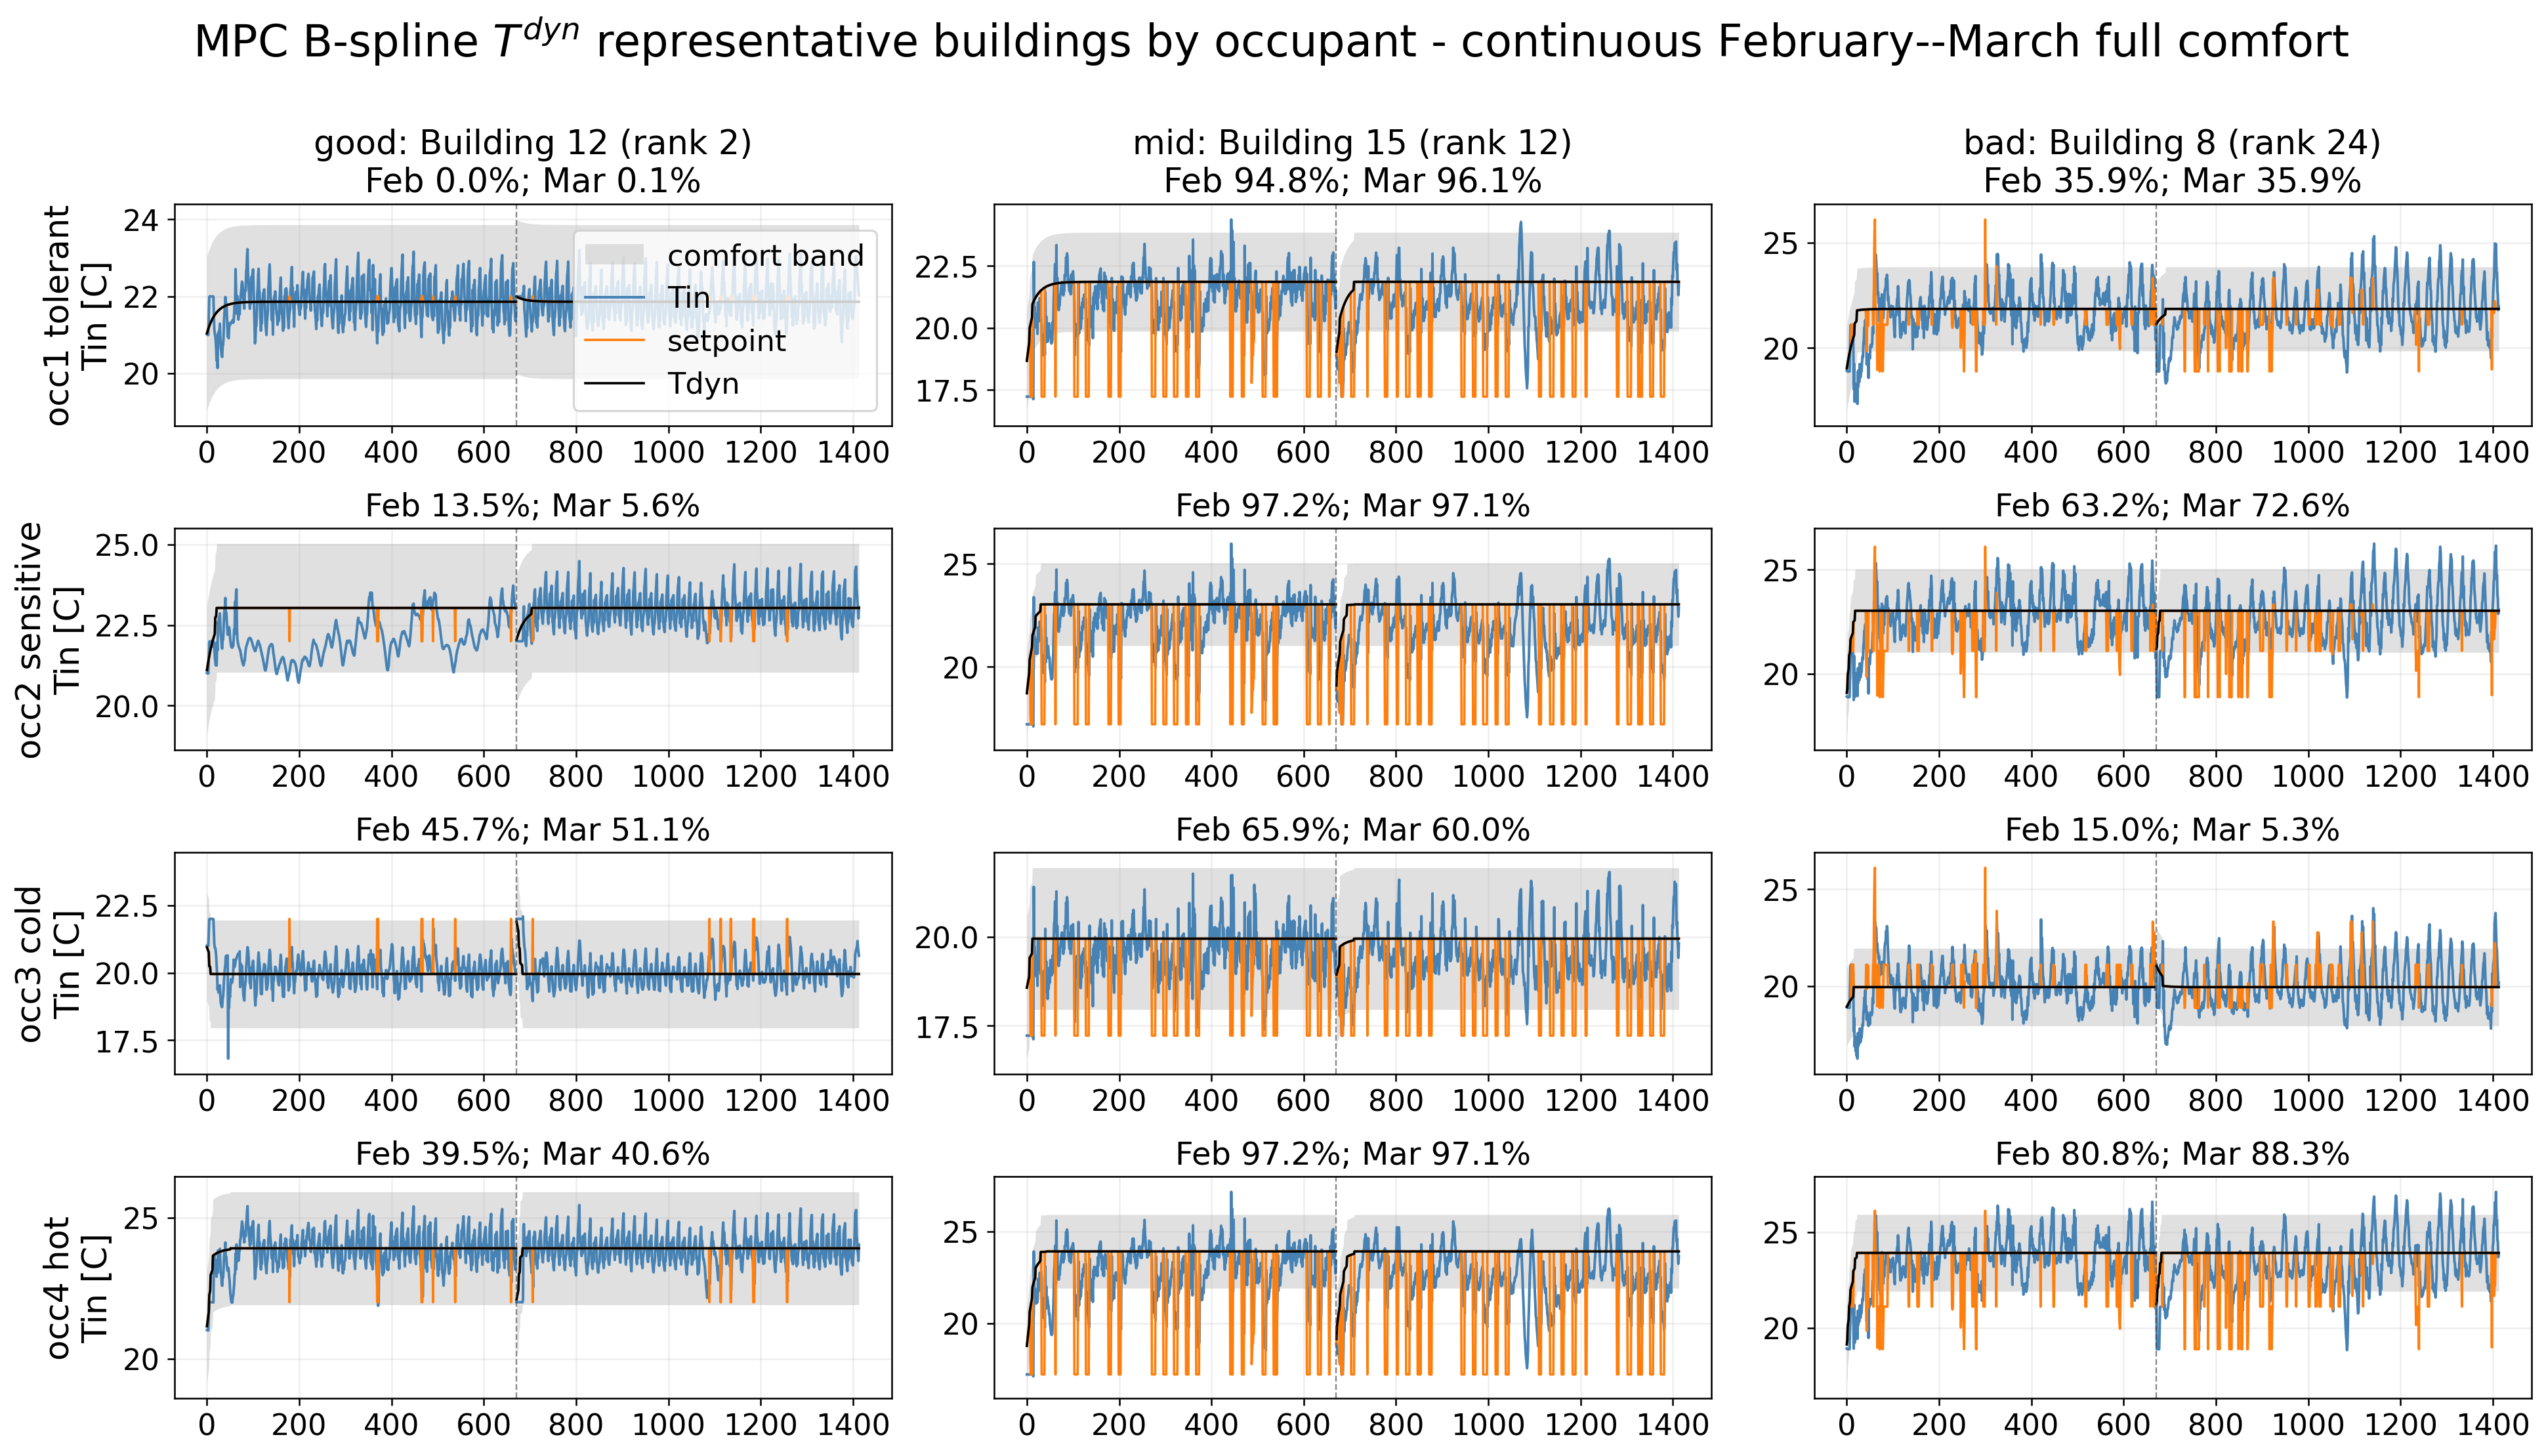

In [6]:
display(Image(filename=str(FIGURES / 'ce1_thesis_final_results/thesis_mpc_occupant_selected_month.png'))) 

## MPC daily comfort profiles by occupant

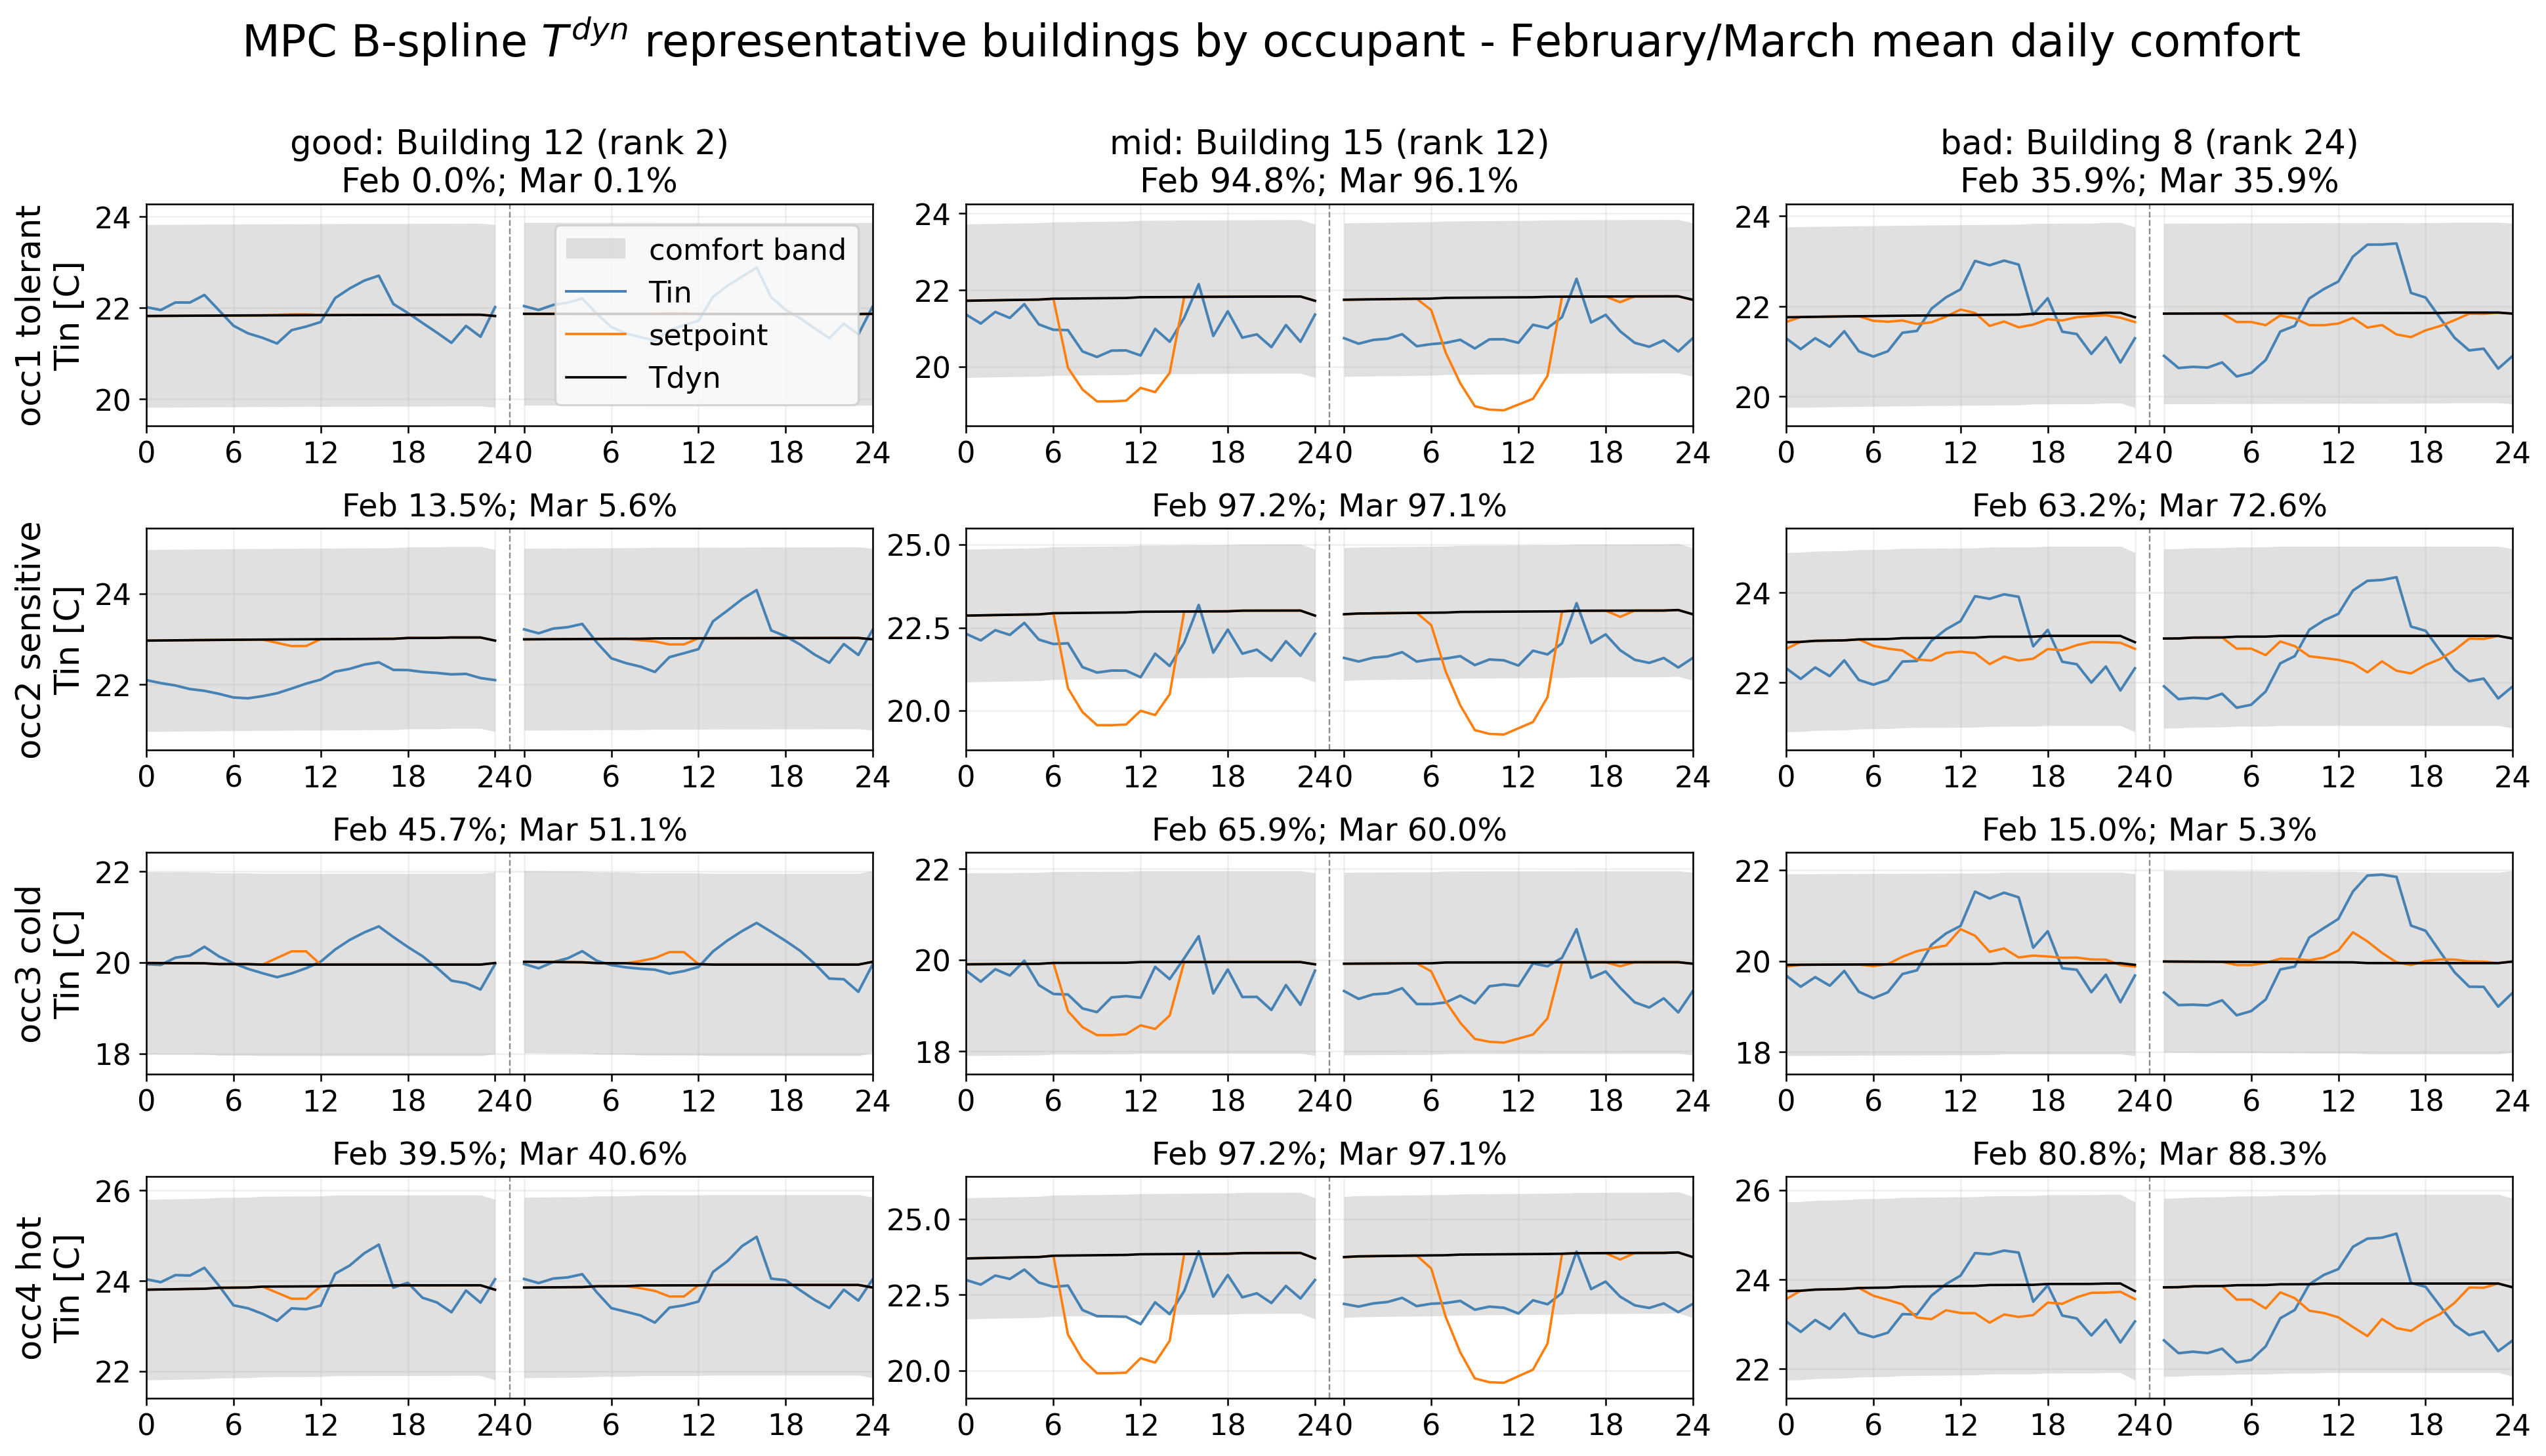

In [7]:
display(Image(filename=str(FIGURES / 'ce1_thesis_final_results/thesis_mpc_occupant_selected_mean_daily.png'))) 

## MPC occupant load profiles

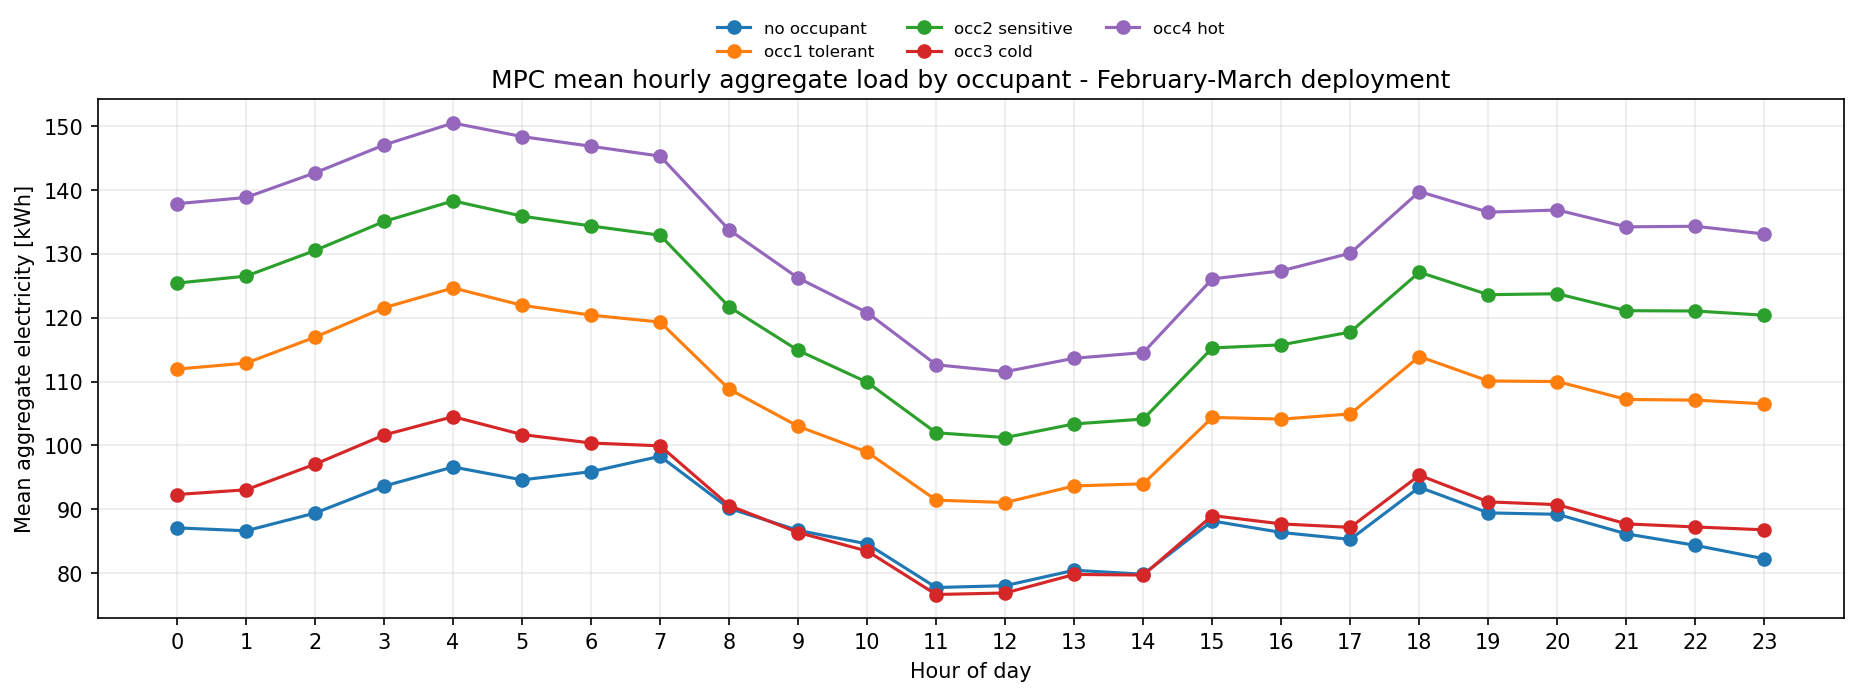

In [8]:
display(Image(filename=str(FIGURES / 'ce1_thesis_final_results/thesis_mpc_occupant_mean_hourly_load_feb_mar.png'))) 

## MPC building-level distributions by occupant

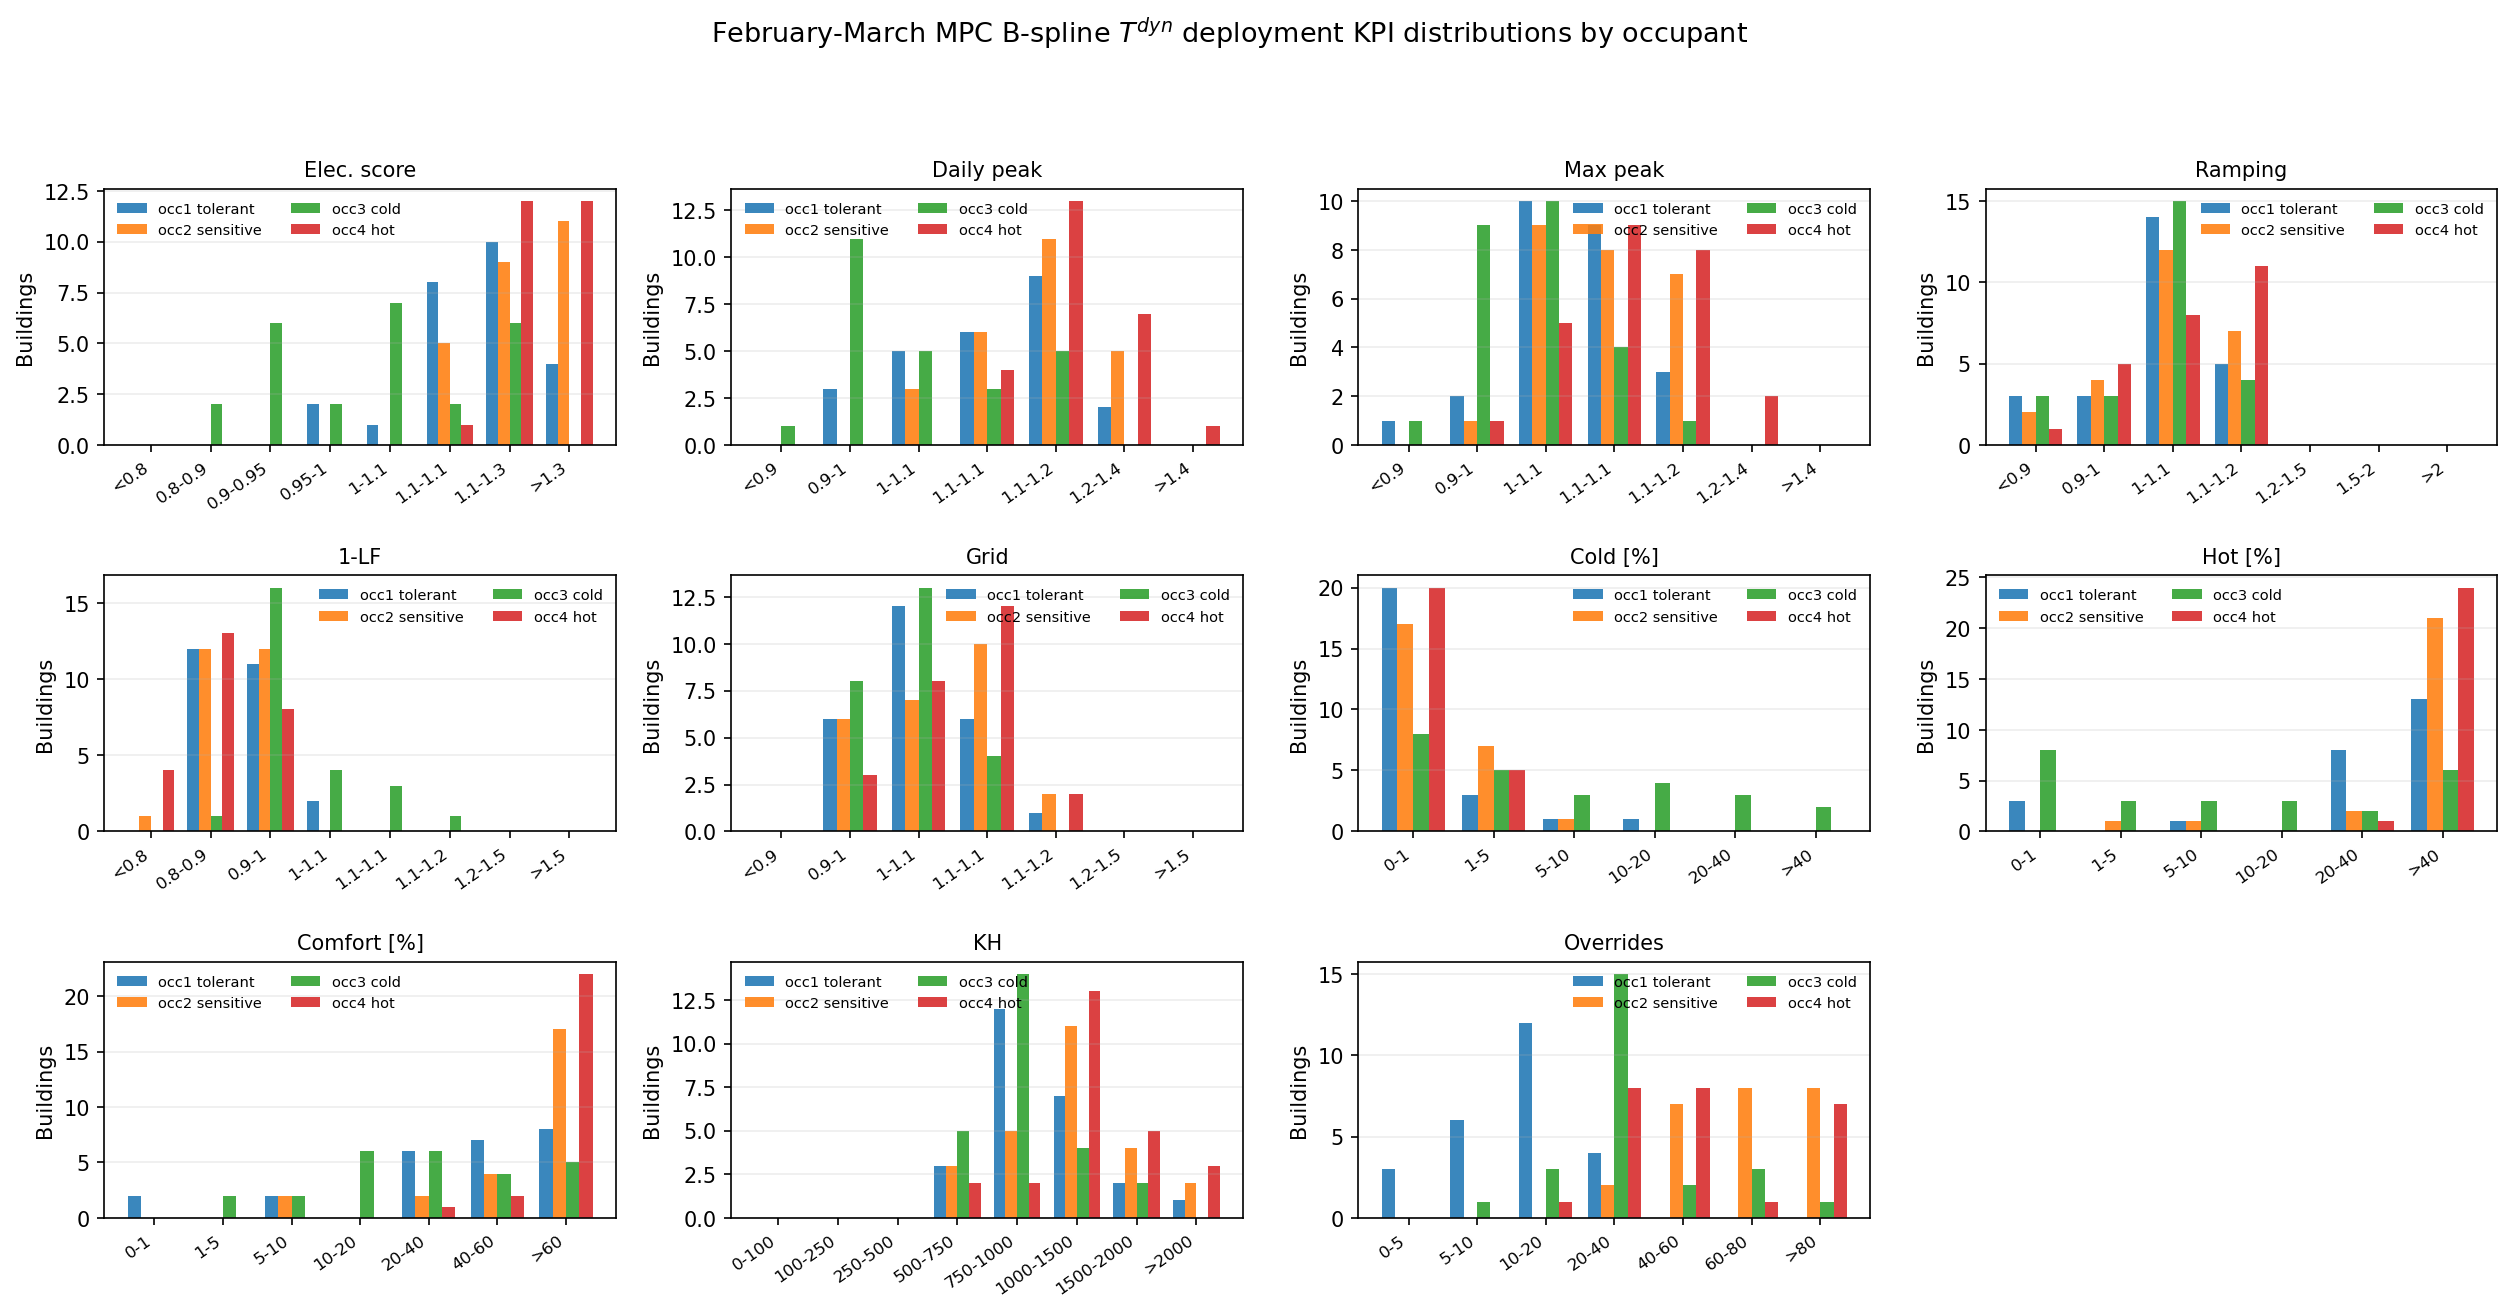

In [9]:
display(Image(filename=str(FIGURES / 'ce1_thesis_final_results/feb_mar_mpc_bspline_tdyn_table_viii_hist_by_occupant.png'))) 

The distribution figure retains its original export filename (`table_viii`); the final PDF labels the occupant comparison **Table IX**. For occupancy prediction validation, see [the dedicated validation notebook](09_bspline_occupancy_validation.ipynb), which distinguishes full-series fitting from January-only holdout fitting.